# StudyMate — Lecture-image recognition (CNN) · Colab
**AI Lab · Project 1E · Course Study Assistant** — Benha University · https://github.com/pikachu8240/StudyMate

**Problem:** the site's text search cannot "see" pictures, diagrams, graphs and screenshots inside slides, so a question about a figure finds nothing.
**Solution in this notebook:** a CNN that *recognises the images that appear in the lectures*:

1. **Extract** every embedded picture from the lecture PDFs (and remember its lecture / slide).
2. **Clean** the data: drop logos/backgrounds (same picture repeated on many slides) and tiny icons, remove duplicates.
3. **Train a CNN classifier** — *which lecture does this image belong to?* (transfer learning with MobileNetV2 when ImageNet weights can be downloaded — always the case on Colab; otherwise a small CNN trained from scratch).
4. **Image search:** the CNN's embedding vector is used to find the **most similar lecture slides** for any new image (a photo of a slide, a screenshot of a figure). This is what lets the website answer an *image* question with "see lecture X, slide Y".
5. **Evaluate** with a hold-out test and with *distorted* queries (crop / brightness / blur / rotation) that imitate a phone photo.
6. **Export** `image_model.keras` + `image_index.npz` + metrics for the TA and for integration in the site.

Run `Runtime ▸ Change runtime type ▸ GPU` (optional, speeds up) then `Runtime ▸ Run all`.

In [1]:
import os, sys, subprocess
REPO = "https://github.com/pikachu8240/StudyMate.git"
if not os.path.exists("core/search.py"):
    if not os.path.exists("StudyMate"):
        subprocess.run(["git", "clone", "--depth", "1", REPO], check=True)
    os.chdir("StudyMate")
sys.path.insert(0, os.getcwd())
!apt-get -qq install -y poppler-utils tesseract-ocr > /dev/null 2>&1
!pip -q install pdfplumber pdf2image wordninja pypdf rank_bm25 2>/dev/null
print("Project folder:", os.getcwd())

Project folder: /tmp/nbrun


In [2]:
import io, json, glob, re, random, shutil, hashlib, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import pdfplumber
from pdf2image import convert_from_path
from PIL import Image, ImageFilter, ImageEnhance
import config
from core import autocourse
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
SEED = 0; random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs("results", exist_ok=True)
print("TensorFlow", tf.__version__, "| GPU:", bool(tf.config.list_physical_devices("GPU")))

I0000 00:00:1794441194.996981    1289 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow 2.21.0 | GPU: False


I0000 00:00:1794441195.817420    1289 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1 · Choose the course (built-in `AI` / `MAM336`, or upload your own lecture PDFs)

In [3]:
COURSE = "AI"
try:                                                   # OPTIONAL on Colab: upload your own PDFs
    from google.colab import files
    if input("Upload your own lecture PDFs? (y/N) ").strip().lower() == "y":
        up = files.upload(); COURSE = "MYCOURSE"
        shutil.rmtree(config.course_paths(COURSE).data, ignore_errors=True)
        for n, b in up.items(): autocourse.save_lecture(COURSE, n, b)
except ImportError:
    pass
PDFS = sorted(glob.glob(str(config.course_paths(COURSE).lectures / "*.pdf")))
print(COURSE, "->", len(PDFS), "lecture PDFs")

AI -> 7 lecture PDFs


## 2 · Extract the images from the PDFs
`pdfplumber` gives the bounding box of every embedded picture on every page; the page is rendered with `pdf2image` and the box is cropped
(so vector diagrams drawn over the picture are included too).

In [4]:
DPI, MIN_SIDE = 80, 48
def lecture_no(path):
    return autocourse.lecture_number(os.path.basename(path)) or 0

records, crops = [], []
for pdf in PDFS:
    lec = lecture_no(pdf)
    pages = convert_from_path(pdf, dpi=DPI)
    with pdfplumber.open(pdf) as doc:
        for pno, page in enumerate(doc.pages):
            img_page = pages[pno]; sx = img_page.width / float(page.width); sy = img_page.height / float(page.height)
            for im in page.images:
                x0, x1, top, bot = [im[k] for k in ("x0", "x1", "top", "bottom")]
                box = tuple(int(v) for v in (max(0, x0*sx), max(0, top*sy), min(img_page.width, x1*sx), min(img_page.height, bot*sy)))
                if box[2]-box[0] < MIN_SIDE or box[3]-box[1] < MIN_SIDE: continue
                crop = img_page.crop(box).convert("RGB")
                records.append({"lecture": lec, "slide": pno + 1, "w": crop.width, "h": crop.height}); crops.append(crop)
df = pd.DataFrame(records)
print("Raw extracted images:", len(df), "| from", df.lecture.nunique(), "lectures")

Raw extracted images: 292 | from 7 lectures


## 3 · Clean the data
* **Logos / template pictures** appear on many slides ⇒ same *average-hash* repeated ⇒ removed (they say nothing about the lecture).
* **Duplicates** inside a lecture are kept once.

In [5]:
def ahash(im, n=8):
    g = np.asarray(im.convert("L").resize((n, n), Image.BILINEAR), dtype=np.float32)
    return "".join("1" if v else "0" for v in (g > g.mean()).flatten())
df["hash"] = [ahash(c) for c in crops]
freq = df.groupby("hash")["slide"].transform("count")
keep = (freq < 4) & ~df.duplicated(["lecture", "hash"])
print(f"removed {int((~keep).sum())} logos/duplicates, kept {int(keep.sum())}")
df = df[keep].reset_index(drop=True); crops = [c for c, k in zip(crops, keep) if k]
print(df.lecture.value_counts().sort_index().to_string())

removed 42 logos/duplicates, kept 250
lecture
1    56
2    33
3    19
4    31
5    30
6    58
7    23


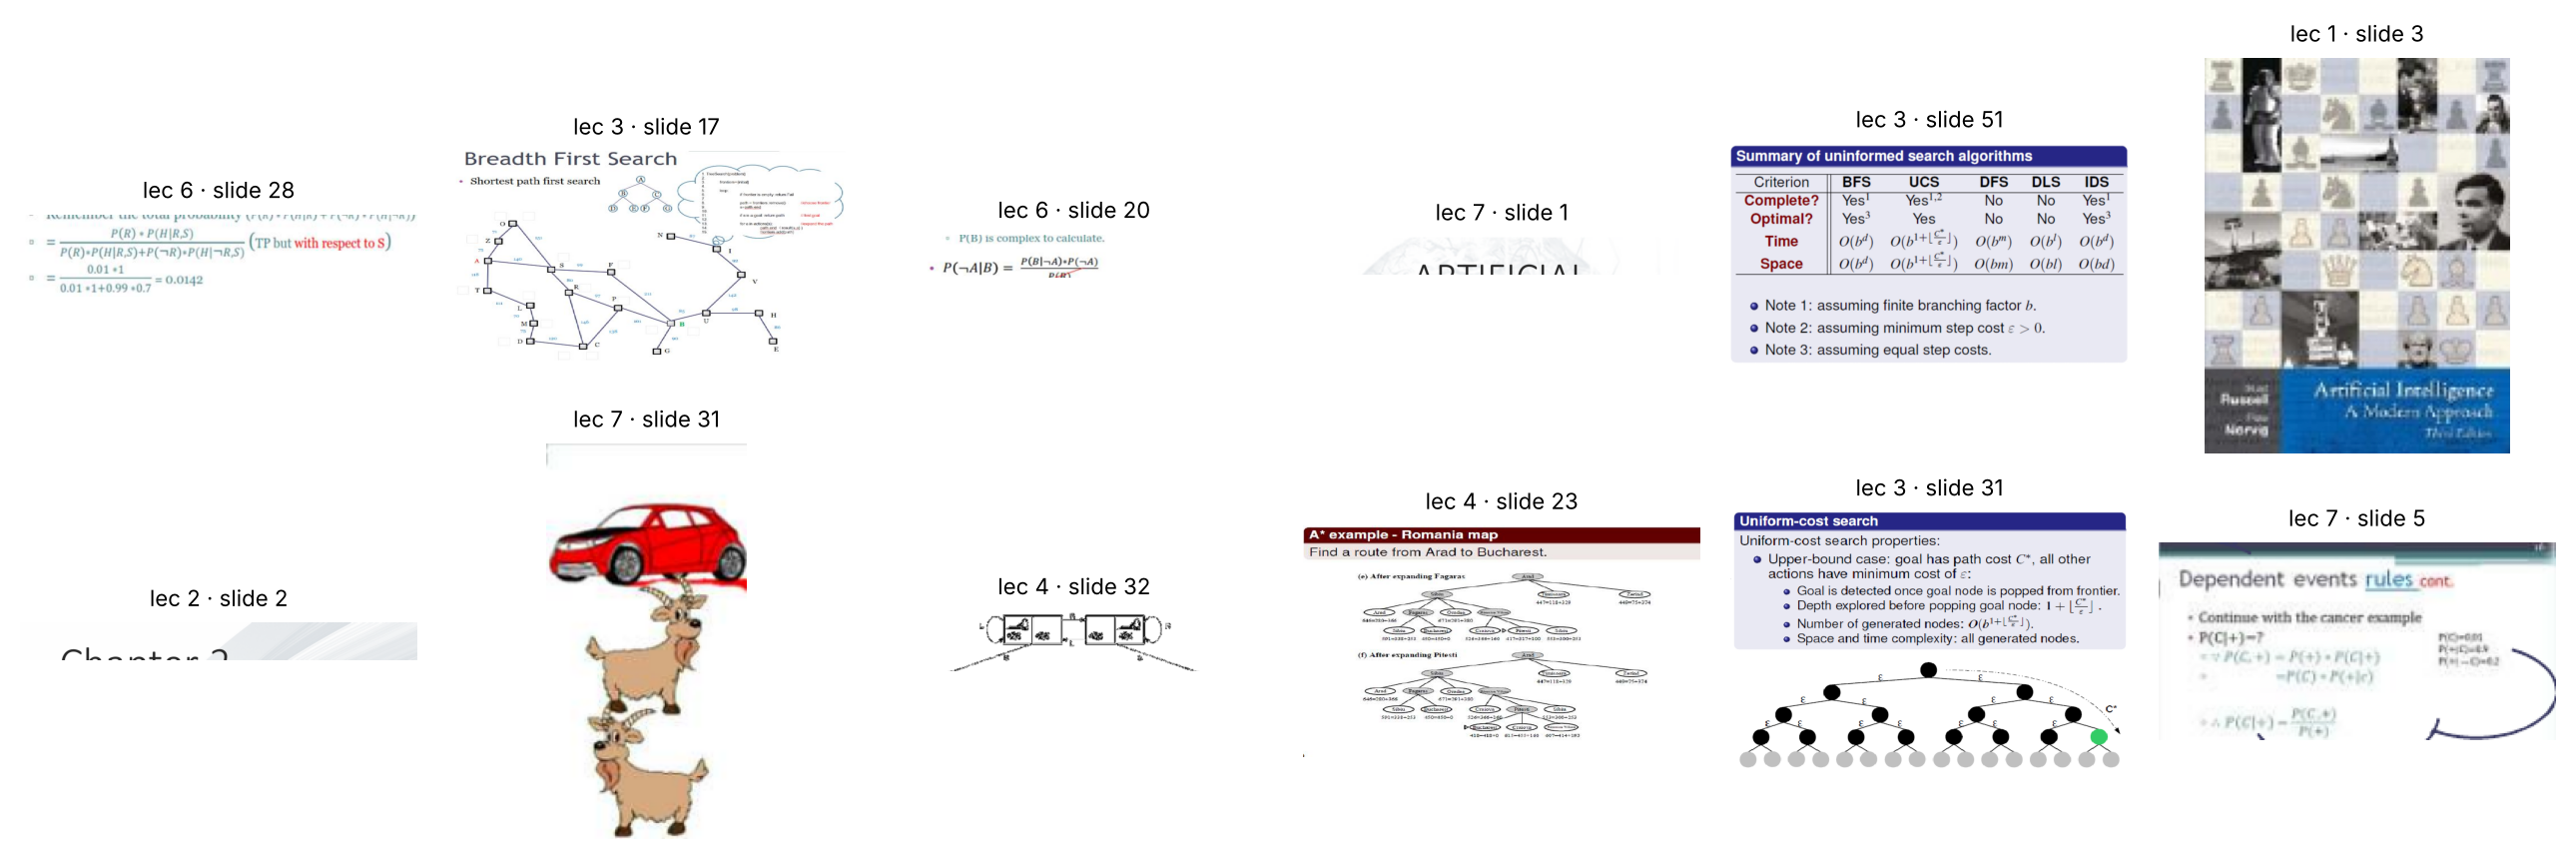

In [6]:
fig, axs = plt.subplots(2, 6, figsize=(13, 4.4))
for ax, i in zip(axs.flat, random.sample(range(len(crops)), min(12, len(crops)))):
    ax.imshow(crops[i]); ax.set_title(f"lec {df.lecture[i]} · slide {df.slide[i]}", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.savefig("results/sample_images.png", dpi=120); plt.show()

## 4 · Build the dataset (resize, split, augment)

In [7]:
S = 96
X = np.stack([np.asarray(c.resize((S, S), Image.BILINEAR), dtype=np.uint8) for c in crops])
classes = [int(c) for c in sorted(df.lecture.unique())]; cid = {l: i for i, l in enumerate(classes)}
y = df.lecture.map(cid).to_numpy()
from sklearn.model_selection import train_test_split
idx = np.arange(len(X))
tr, te = train_test_split(idx, test_size=0.2, stratify=y, random_state=SEED)
tr, va = train_test_split(tr, test_size=0.2, stratify=y[tr], random_state=SEED)
print("train/val/test:", len(tr), len(va), len(te), "| classes:", classes)
augment = keras.Sequential([layers.RandomFlip("horizontal"), layers.RandomRotation(0.08), layers.RandomZoom(0.15),
                            layers.RandomContrast(0.25), layers.RandomTranslation(0.08, 0.08)])

train/val/test: 160 40 50 | classes: [1, 2, 3, 4, 5, 6, 7]


## 5 · The CNN
MobileNetV2 (ImageNet weights) + a small head when the weights can be downloaded (Colab). If not (offline), a 4-block CNN trained from scratch is used —
the rest of the notebook is identical. The layer before the output (`embedding`, 128-d) is used later for image search.

In [8]:
def build_model(n_classes):
    inp = keras.Input((S, S, 3))
    try:
        base = keras.applications.MobileNetV2(input_shape=(S, S, 3), include_top=False, weights="imagenet")
        base.trainable = False
        x = keras.applications.mobilenet_v2.preprocess_input(augment(inp)); x = base(x, training=False); kind = "MobileNetV2 (ImageNet transfer learning)"
        x = layers.GlobalAveragePooling2D()(x)
    except Exception as e:
        kind = "small CNN from scratch (ImageNet weights not available here)"
        x = layers.Rescaling(1/255)(augment(inp))
        for f in (32, 64, 96, 128):
            x = layers.Conv2D(f, 3, padding="same", activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.MaxPooling2D()(x)
        x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    emb = layers.Dense(128, activation="relu", name="embedding")(x)
    out = layers.Dense(n_classes, activation="softmax")(layers.Dropout(0.3)(emb))
    m = keras.Model(inp, out); m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return m, kind
model, KIND = build_model(len(classes)); print("Model:", KIND, "| parameters:", f"{model.count_params():,}")

Model: small CNN from scratch (ImageNet weights not available here) | parameters: 204,199


Epoch 1/40


5/5 - 3s - 661ms/step - accuracy: 0.1875 - loss: 2.3207 - val_accuracy: 0.2250 - val_loss: 1.9217


Epoch 2/40


5/5 - 1s - 199ms/step - accuracy: 0.3562 - loss: 1.9893 - val_accuracy: 0.1500 - val_loss: 1.9298


Epoch 3/40


5/5 - 1s - 194ms/step - accuracy: 0.3938 - loss: 1.7040 - val_accuracy: 0.1250 - val_loss: 1.9442


... (66 outputs left out)

Epoch 37/40


5/5 - 1s - 241ms/step - accuracy: 0.8125 - loss: 0.5108 - val_accuracy: 0.2500 - val_loss: 3.3276


Epoch 38/40


5/5 - 1s - 258ms/step - accuracy: 0.8188 - loss: 0.5516 - val_accuracy: 0.3250 - val_loss: 5.5249


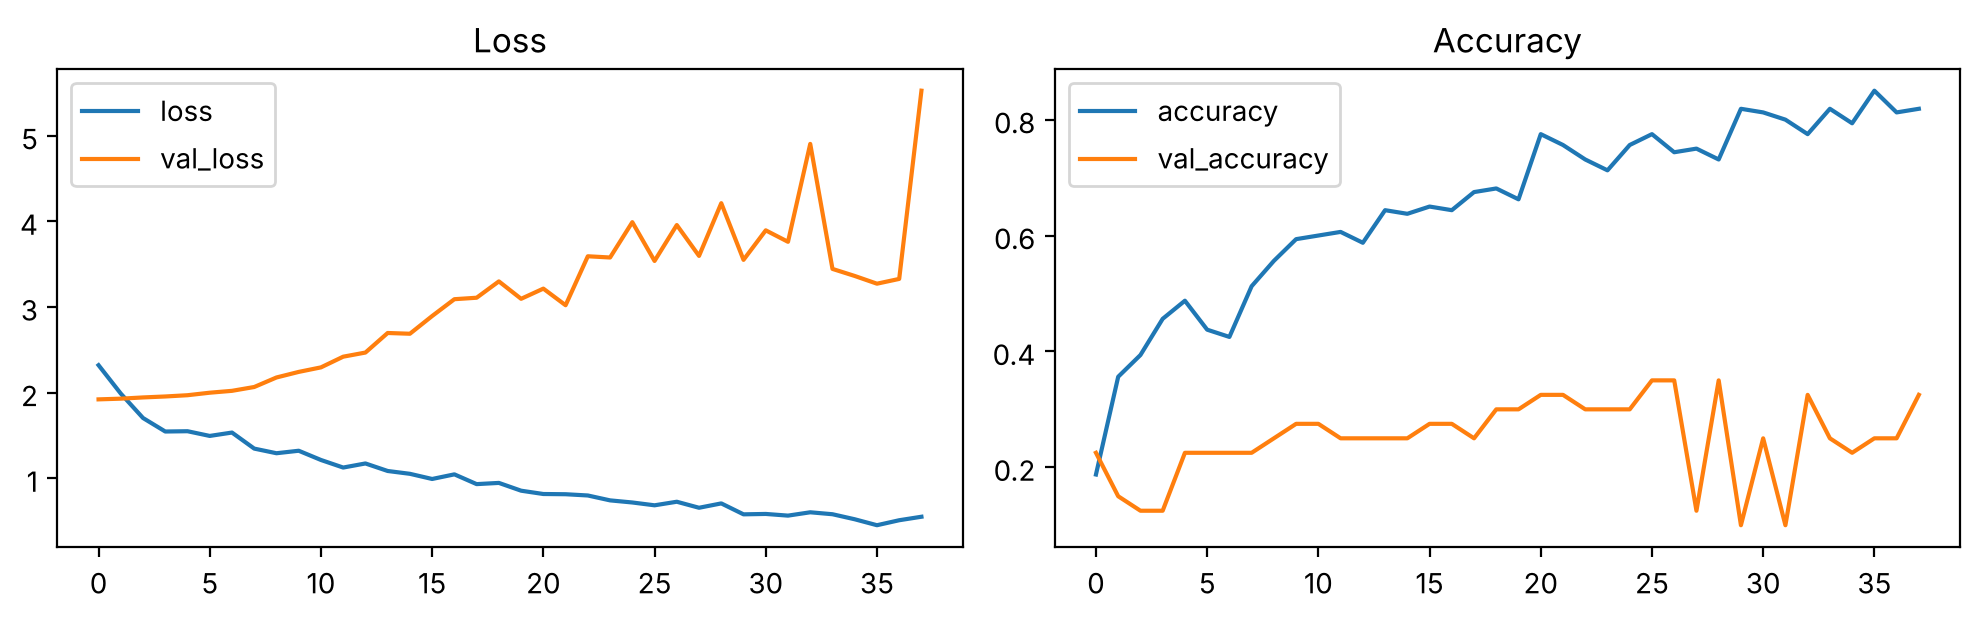

In [9]:
cb = [keras.callbacks.EarlyStopping(patience=12, restore_best_weights=True, monitor="val_accuracy")]
hist = model.fit(X[tr], y[tr], validation_data=(X[va], y[va]), epochs=40, batch_size=32, callbacks=cb, verbose=2)
h = pd.DataFrame(hist.history)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
h[["loss", "val_loss"]].plot(ax=ax[0], title="Loss"); h[["accuracy", "val_accuracy"]].plot(ax=ax[1], title="Accuracy")
plt.tight_layout(); plt.savefig("results/training_curves.png", dpi=120); plt.show()

## 6 · Evaluate on the untouched test images

Test accuracy (which lecture is this image from?): 26.0%  on 50 images
              precision    recall  f1-score   support

   lecture 1       0.00      0.00      0.00        11
   lecture 2       0.29      0.29      0.29         7
   lecture 3       0.00      0.00      0.00         4
   lecture 4       0.00      0.00      0.00         6
   lecture 5       0.00      0.00      0.00         6
   lecture 6       0.26      1.00      0.41        11
   lecture 7       0.00      0.00      0.00         5

    accuracy                           0.26        50
   macro avg       0.08      0.18      0.10        50
weighted avg       0.10      0.26      0.13        50



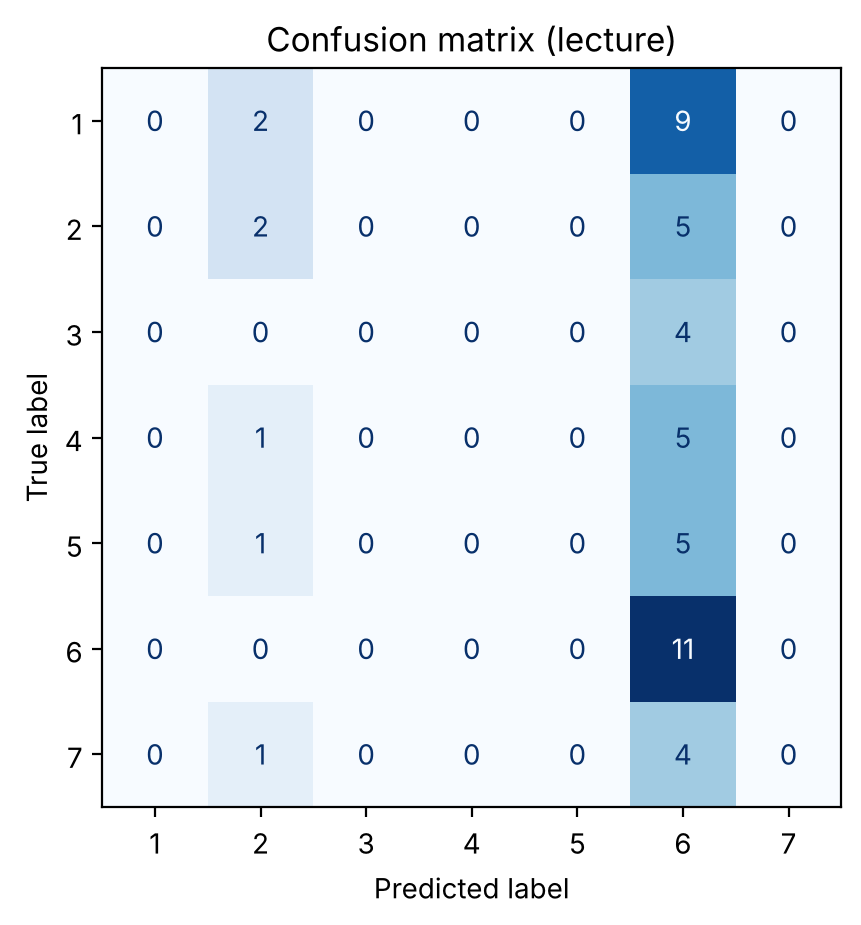

In [10]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
pred = model.predict(X[te], verbose=0).argmax(1)
acc = float((pred == y[te]).mean())
print(f"Test accuracy (which lecture is this image from?): {acc*100:.1f}%  on {len(te)} images")
rep = classification_report(y[te], pred, target_names=[f"lecture {c}" for c in classes], output_dict=True, zero_division=0)
print(classification_report(y[te], pred, target_names=[f"lecture {c}" for c in classes], zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y[te], pred), display_labels=classes).plot(cmap="Blues", colorbar=False)
plt.title("Confusion matrix (lecture)"); plt.savefig("results/confusion_matrix.png", dpi=120); plt.show()

## 7 · Image search: find the slide of an image
The 128-d embedding of every extracted image is stored in an index (with its lecture & slide). A query image is embedded and compared by cosine similarity.
We test it with **distorted copies** of the held-out images (crop, rotation, blur, brightness) to imitate a phone photo of the screen.

In [11]:
embedder = keras.Model(model.input, model.get_layer("embedding").output)
def embed(arr):
    e = embedder.predict(arr, verbose=0); return e / (np.linalg.norm(e, axis=1, keepdims=True) + 1e-9)
index_vecs = embed(X)
meta = df[["lecture", "slide"]].to_dict("records")
def distort(im, rng):
    w, h = im.size; dx, dy = int(w*rng.uniform(0, .1)), int(h*rng.uniform(0, .1))
    im = im.crop((dx, dy, w - dx, h - dy)).rotate(rng.uniform(-8, 8), expand=False)
    im = ImageEnhance.Brightness(im).enhance(rng.uniform(.7, 1.3))
    return im.filter(ImageFilter.GaussianBlur(rng.uniform(0, 1.5)))
rng = random.Random(SEED)
Q = np.stack([np.asarray(distort(crops[i], rng).resize((S, S)), dtype=np.uint8) for i in te])
qv = embed(Q); sim = qv @ index_vecs.T
for k_i, i in enumerate(te): sim[k_i, i] = sim[k_i, i]         # the same image IS in the index (as in the real site)
top = np.argsort(-sim, 1)[:, :3]
top1_img = np.mean([t[0] == i for t, i in zip(top, te)]); top3_img = np.mean([i in t for t, i in zip(top, te)])
top1_lec = np.mean([meta[t[0]]["lecture"] == meta[i]["lecture"] for t, i in zip(top, te)])
print(f"Distorted-photo search: exact image Top-1 {top1_img*100:.1f}% | Top-3 {top3_img*100:.1f}% | correct lecture at rank 1: {top1_lec*100:.1f}%")

Distorted-photo search: exact image Top-1 10.0% | Top-3 16.0% | correct lecture at rank 1: 38.0%


**Baseline for comparison:** a hand-made embedding (24×24 grey thumbnail + colour histogram, no learning). The better of the two is exported as the site's image index — a trained CNN is *not* automatically better with only a few hundred images, so we measure instead of assuming.

In [12]:
def classic(im_arr):
    out = []
    for a in im_arr:
        im = Image.fromarray(a); g = np.asarray(im.convert("L").resize((24, 24)), dtype=np.float32).flatten()
        g = (g - g.mean()) / (g.std() + 1e-6)
        hst = np.concatenate([np.histogram(np.asarray(im)[..., c], bins=8, range=(0, 255))[0] for c in range(3)]).astype(np.float32); hst /= hst.sum() + 1e-9
        out.append(np.concatenate([g / np.sqrt(len(g)), hst * 2]))
    v = np.array(out); return v / (np.linalg.norm(v, axis=1, keepdims=True) + 1e-9)
cv_idx, cv_q = classic(X), classic(Q)
sim2 = cv_q @ cv_idx.T; top2 = np.argsort(-sim2, 1)[:, :3]
c1 = np.mean([t[0] == i for t, i in zip(top2, te)]); c3 = np.mean([i in t for t, i in zip(top2, te)])
c_lec = np.mean([meta[t[0]]["lecture"] == meta[i]["lecture"] for t, i in zip(top2, te)])
cmp_tbl = pd.DataFrame({"CNN embedding": [top1_img, top3_img, top1_lec], "Hand-made (pixels + colour)": [c1, c3, c_lec]},
                       index=["exact image Top-1", "exact image Top-3", "correct lecture @1"]).mul(100).round(1)
print(cmp_tbl)
BEST = "cnn" if top1_img >= c1 else "classic"; print("Exported index uses:", BEST)

                    CNN embedding  Hand-made (pixels + colour)
exact image Top-1            10.0                         24.0
exact image Top-3            16.0                         30.0
correct lecture @1           38.0                         38.0
Exported index uses: classic


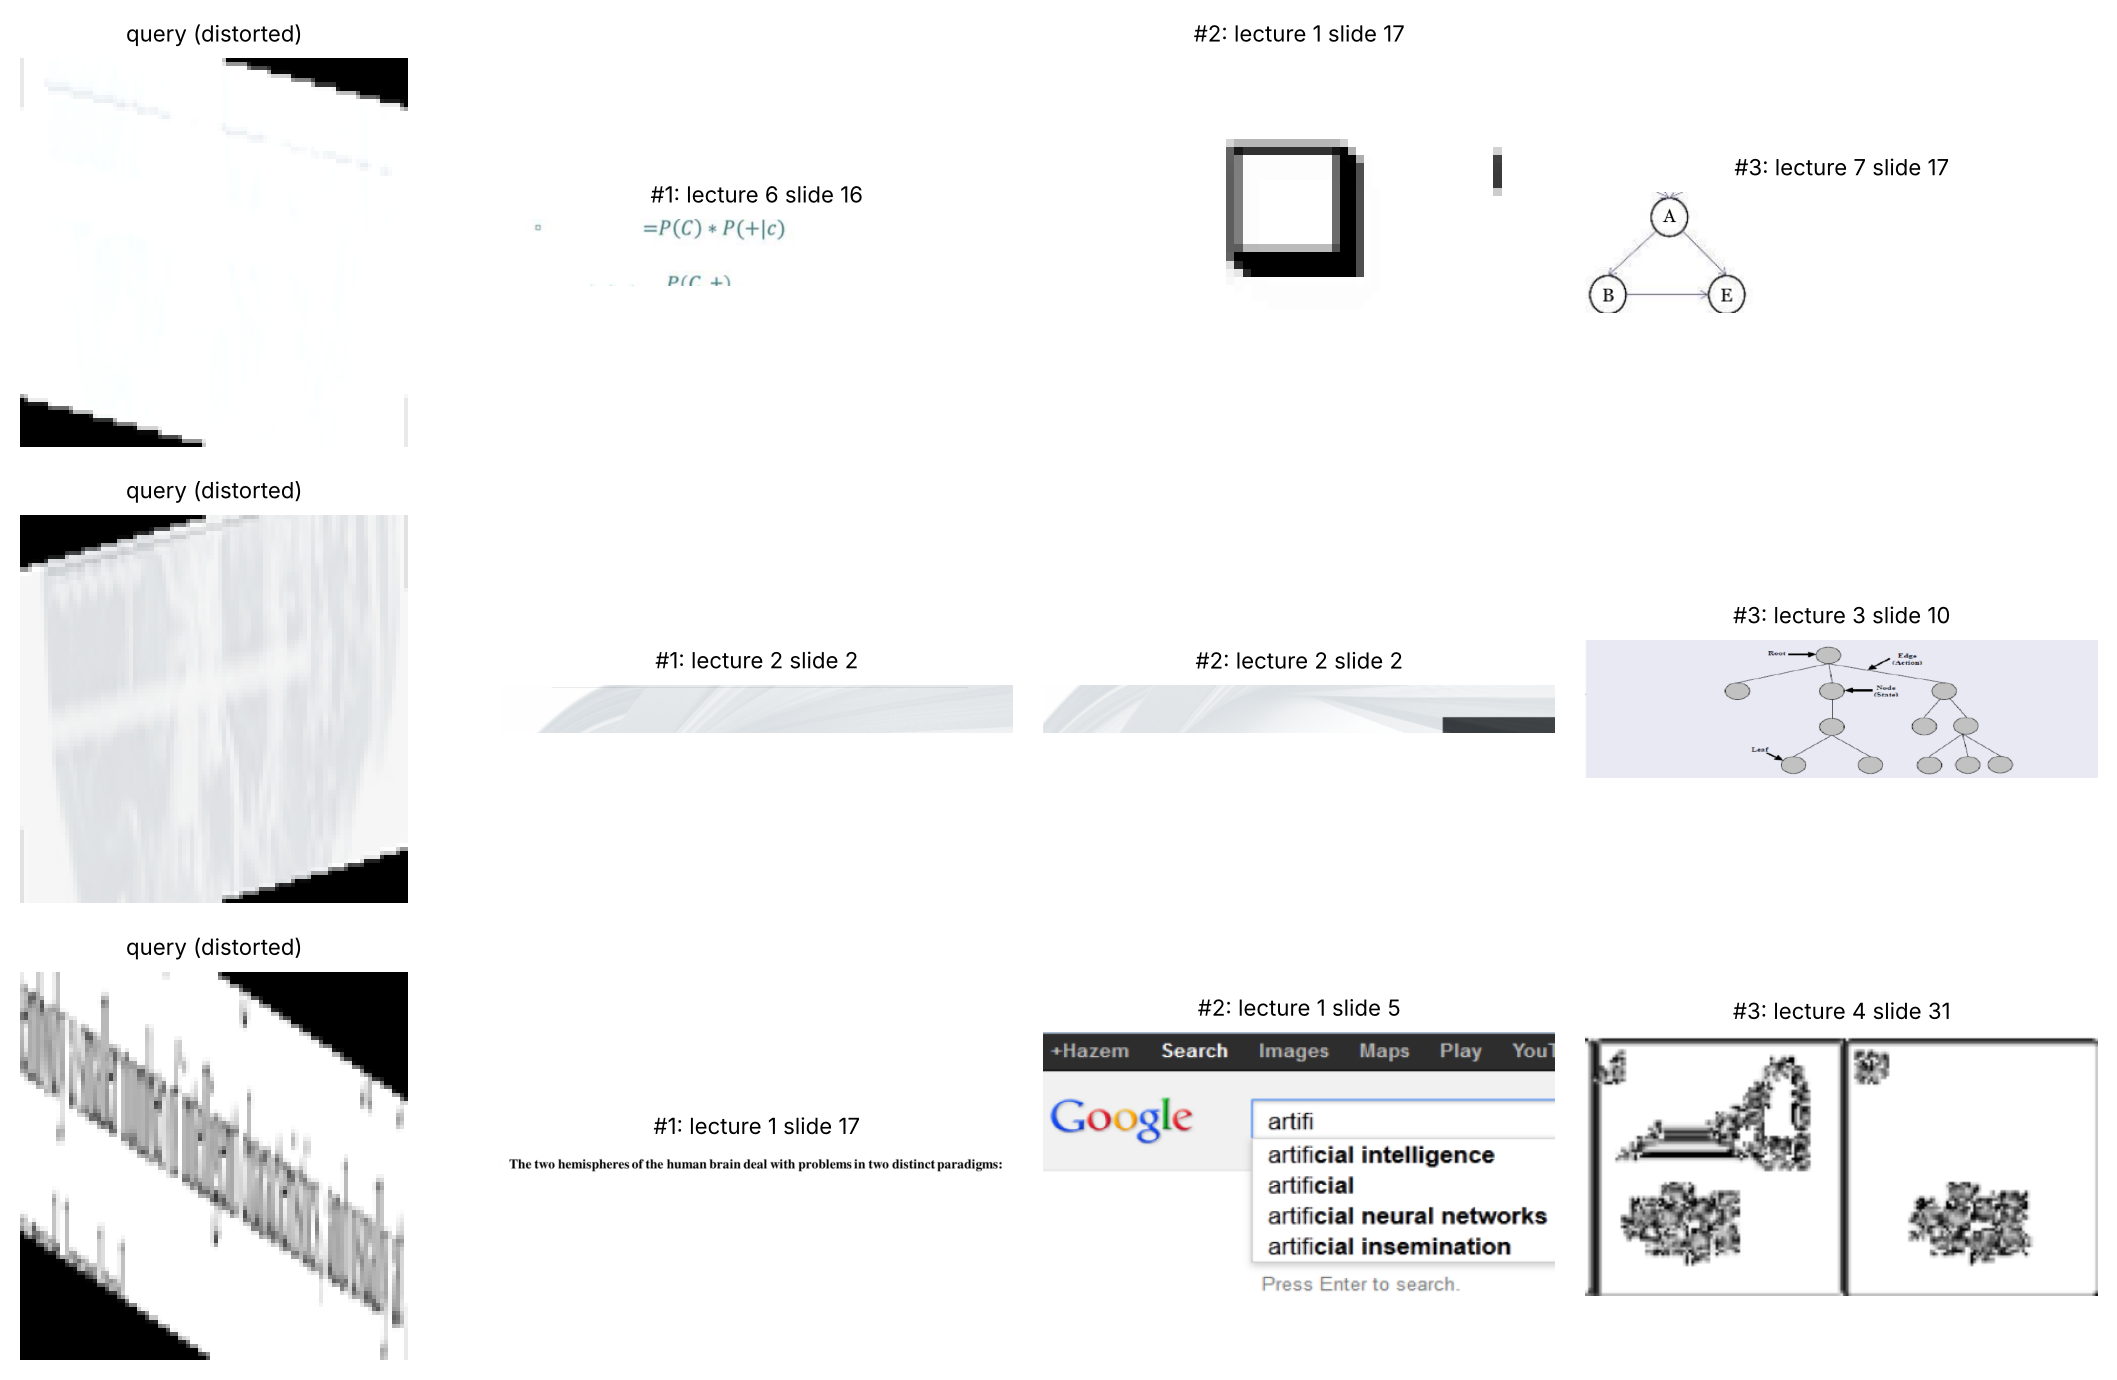

In [13]:
fig, axs = plt.subplots(3, 4, figsize=(11, 7))
for r, k_i in enumerate(random.sample(range(len(te)), 3)):
    axs[r, 0].imshow(Q[k_i]); axs[r, 0].set_title("query (distorted)", fontsize=8)
    for c, j in enumerate(top[k_i]):
        axs[r, c+1].imshow(crops[j]); axs[r, c+1].set_title(f"#{c+1}: lecture {meta[j]['lecture']} slide {meta[j]['slide']}", fontsize=8)
for a in axs.flat: a.axis("off")
plt.tight_layout(); plt.savefig("results/image_search_examples.png", dpi=120); plt.show()

## 8 · Read the text inside the pictures (OCR) → `figure_text.json`
The normal extraction only sees real text, so a slide whose content is a pasted picture (a map, a diagram with labels, a screenshot of a table) was invisible to the search. Here every picture of every slide is read with **Tesseract**: logos and repeated pictures are dropped, only confident words (confidence ≥ 60) are kept, and the result is saved per slide (`L01S05` = lecture 1, slide 5). **Import `figure_text.json` on the site's *AI models* page** and the search will find those slides. Formulas are not understood by OCR; only their words (names, labels) are kept.

In [ ]:
from core import figures
from pathlib import Path
figure_text = {}
for pdf in PDFS:
    lec = lecture_no(pdf)
    for page_no, txt in figures.pdf_figure_text(pdf, Path("ocr_cache")).items():
        figure_text[f"L{lec:02d}S{page_no:02d}"] = txt
os.makedirs("results", exist_ok=True)
json.dump(figure_text, open("results/figure_text.json", "w"), ensure_ascii=False, indent=1)
print(f"{len(figure_text)} slides have text inside their pictures")
for k in list(figure_text)[:5]:
    print(" ", k, "->", figure_text[k][:110])

## 9 · Export for the TA and for the website
* `image_model.keras` – the trained CNN · `image_index.npz` – embeddings + (lecture, slide) of every lecture image · `image_metrics.json` – numbers above · `figure_text.json` – text read from the pictures.
* **How the site uses them:** open the site's *AI models* page → *Google Colab notebooks* → import the `.zip`. The metrics are shown and compared, and `figure_text.json` is added to the search index.
* **Integration plan (site):** at upload time extract the images (cells 2–3), embed them, store `image_index.npz` next to the course; a new "search by image" box embeds the student's picture and shows the top slides — the same flow as cell 7.
* Because the extraction and the index are rebuilt for each uploaded course, the numbers change per course.

In [14]:
model.save("results/image_model.keras")
np.savez_compressed("results/image_index.npz", vecs=(index_vecs if BEST == "cnn" else cv_idx), kind=BEST, lecture=df.lecture.to_numpy(), slide=df.slide.to_numpy())
json.dump({"course": COURSE, "model": KIND, "images": int(len(df)), "classes": [int(c) for c in classes], "test_accuracy": round(acc, 4),
           "search_index_used": BEST, "search_comparison_pct": cmp_tbl.to_dict(), "search_top1_exact": round(float(top1_img), 4), "search_top3_exact": round(float(top3_img), 4), "search_lecture_at_1": round(float(top1_lec), 4),
           "per_class_f1": {k: round(v["f1-score"], 3) for k, v in rep.items() if k.startswith("lecture")}},
          open("results/image_metrics.json", "w"), indent=1)
print(sorted(os.listdir("results")))
try:
    from google.colab import files
    shutil.make_archive("studymate_image_results", "zip", "results"); files.download("studymate_image_results.zip")
except ImportError:
    print("Results are in ./results")

['confusion_matrix.png', 'image_index.npz', 'image_metrics.json', 'image_model.keras', 'image_search_examples.png', 'sample_images.png', 'training_curves.png']
Results are in ./results


In [ ]:
# OPTIONAL - send the results straight to the website (no download / upload by hand).
# Paste SITE and TOKEN from the site: Admin > AI models > "Send results straight from Colab".
SITE, TOKEN = "", ""
if SITE and TOKEN:
    import requests
    shutil.make_archive("_to_site", "zip", "results")
    r = requests.post(SITE.rstrip("/") + "/api/colab-upload", data={"token": TOKEN, "course": COURSE}, files={"file": open("_to_site.zip", "rb")}, timeout=300)
    print(r.status_code, r.text)
else:
    print("SITE / TOKEN empty: use the downloaded .zip with the Import button instead.")